# Manifold Active Learning of a Protein Formulation Phase Map

This case study runs a single active learning campaign on the AFL-agent virtual protein / glycerol / temperature instrument, `ProteinGlycerolTemperaturePhaseMap`, with the *manifold* strategy of the AFL-bioformulations study. The classifier and the benchmark are the same as in the companion notebook, *Grid-Based Active Learning of a Protein Formulation Phase Map*; the two grid searches of the acquisition are replaced by continuous optimisations.

1. **Classifier.** A `DirichletGPExtrapolator` is fit to the measured phase labels on the three-dimensional design space (protein, temperature, glycerol).
2. **Composition.** `BoTorchAcquisition` searches the (protein, glycerol) plane for the composition with the largest *expected* classifier entropy over random temperature profiles.
3. **Temperature profile.** At that composition `SRSFHilbertSphereAcquisitionFunction` optimises a temperature *profile* (a function on [0, 1] mapped onto the temperature range) on the square-root slope function (SRSF) Hilbert sphere, so that the whole sweep of temperatures passes through the most uncertain regions of the phase map. The optimal profile is discretised into the temperatures that are measured.

The two acquisition scores are plain Python functions defined in this notebook. They take the fitted classifier through a `Variable` placeholder that the acquisition ops resolve against the dataset at run time.

## Set Up the Environment

Import the libraries used in the campaign and define every setting in one place. The design-space limits are those of the virtual instrument, `standardize=True` keeps the feature scaling inside the classifier so all values below are in instrument units.

In [1]:
# Uncomment this cell if you need to install AFL-agent with the ``manifold`` extra
# (torch, gpytorch, pyro-ppl, botorch, geoopt, alphashape, trimesh).
# !pip install "AFL-agent[manifold] @ git+https://github.com/usnistgov/afl-agent"

In [2]:
import netCDF4  # noqa: F401  load xarray's NetCDF/HDF5 build before AFL imports h5py; in some
#                               environments the two HDF5 builds conflict and NetCDF reads fail otherwise
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import xarray as xr

from AFL.double_agent.AcquisitionFunction import BoTorchAcquisition
from AFL.double_agent.benchmarking import PhaseMapF1Score
from AFL.double_agent.Generator import CartesianGrid
from AFL.double_agent.Pipeline import Pipeline
from AFL.double_agent.PyTorchExtrapolator import DirichletGPExtrapolator
from AFL.double_agent.representations.functions import SRSFHilbertSphere, SRSFHilbertSphereAcquisitionFunction
from AFL.double_agent.variables import Variable
from AFL.double_agent.VirtualInstruments import ProteinGlycerolTemperaturePhaseMap

from helpers import plot_manifold_iteration, plot_phase_map, plot_score_history  # plotting, see helpers.py in this folder

np.set_printoptions(precision=3, suppress=True)

/home/knv2/codebase/AFL-bioformulations/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:182: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 11040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [3]:
# campaign
SEED = 1000  # numpy / torch seed and the seed of the benchmark test set
N_SAMPLES = 10  # number of compositions (one temperature profile each) to acquire
INITIAL_COMPOSITION = {"protein": 40.0, "glycerol": 5.0}  # the one composition measured before the campaign
INITIAL_TEMPERATURES = [5.0, 10.0, 20.0, 30.0, 40.0, 45.0]  # ... and the temperatures it is measured at
PLOT_EVERY_ITERATION = False  # draw the six-panel figure after every iteration (slower, more output)

# design space
LIMITS = {"protein": (0.5, 75.0), "glycerol": (0.5, 10.0), "temperature": (0.5, 45.0)}
BOUNDS_T = list(LIMITS["temperature"])  # profile values in [0, 1] are mapped onto this range
GRID_STEPS = 20  # 3D grid on which the GP posterior (phase map) is evaluated
COMPOSITION_GRID_STEPS = 10  # 2D grid on which the composition score is reported

# phase classifier
GP_PARAMS = {"method": "mll", "n_iterations": 200, "verbose": False}
MODEL_DIR = tempfile.mkdtemp(prefix="afl_manifold_gp_")  # where the fitted GP is written each iteration

# acquisition
N_SAMPLING_POINTS = 100  # discretisation of a temperature profile on [0, 1]
OPTIMIZE_XY = {"num_restarts": 8, "raw_samples": 64}  # BoTorch optimiser of the composition score
OPTIMIZE_F = {"n_restarts": 8, "n_iterations": 100}  # Riemannian optimiser of the profile score
N_MC_PROFILES = 16  # random profiles averaged in the composition score
PROFILE_SCORE_POWER = 1.0  # exponent on the entropy in profile_score
PROFILE = {"dt": 0.05, "dT": 3.0}  # sampling of the optimal profile and the degC rounding of its temperatures

# benchmark
N_TEST_PER_PHASE = 100  # stratified test points per phase of the F1 score
F1_AVERAGE = "weighted"  # sklearn f1_score averaging: weighted, macro, micro or None (per phase)

## 2. The Virtual Instrument

`ProteinGlycerolTemperaturePhaseMap.measure` exposes one (protein, glycerol) composition at several temperatures and returns one sample per temperature with the simulated scattering, the `design_space` coordinates in the instrument's feature order and the integer phase label in `phases`. The feature order of the instrument is what the pipeline and the scores below work in.

In [4]:
sim = ProteinGlycerolTemperaturePhaseMap()
COMPONENTS = sim.components  # feature order of the instrument: protein, temperature, glycerol
XY = [c for c in COMPONENTS if c != "temperature"]  # composition components: protein, glycerol
T_INDEX = COMPONENTS.index("temperature")
COMPONENTS

['protein', 'temperature', 'glycerol']

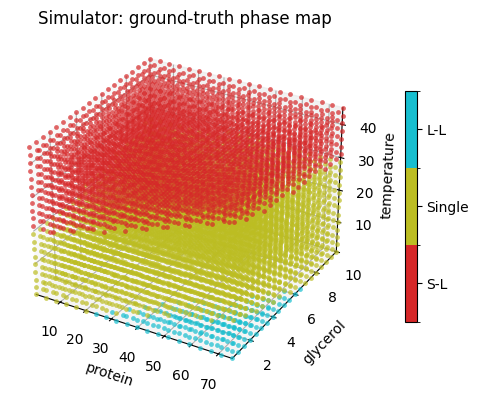

In [5]:
from AFL.double_agent.benchmarking import virtual_instrument_labels

grid_axes = [np.linspace(*LIMITS[c], GRID_STEPS) for c in COMPONENTS]
grid = np.stack(np.meshgrid(*grid_axes, indexing="ij"), axis=-1).reshape(-1, len(COMPONENTS))
true_labels = virtual_instrument_labels(sim, grid)

plot_phase_map(grid, true_labels, LIMITS, COMPONENTS)
plt.show()

## Define the Acquisition Scores

Both scores reduce to the same quantity: the classifier entropy along temperature profiles at a composition. 

A profile is a point `q` on the SRSF Hilbert sphere; `manifold.srsf_to_function(q)` turns it back into a function on [0, 1] whose values are mapped onto the temperature range. The design points are assembled in the instrument's feature order and passed to `model.predict`.

* `composition_score` is the `BoTorchAcquisition` objective: the mean entropy over `N_MC_PROFILES` random profiles. The same profiles are drawn on every call so the score is a smooth function of the composition for the gradient-based optimiser.
* `profile_score` is the `SRSFHilbertSphereAcquisitionFunction` objective: the mean entropy along each candidate profile at the chosen composition. `power=1` is the plain mean; larger values favour profiles with a few very uncertain points.
* `get_temperature_profile` discretises the optimal profile into the unique, rounded temperatures that are measured.

`phase_model` and `composition_next` are `Variable` placeholders. The ops resolve them against the dataset while they calculate: the model reference written by the extrapolator loads into the fitted classifier and the composition chosen in stage 1 becomes a tensor.

In [6]:
MANIFOLD = SRSFHilbertSphere(n_sampling_points=N_SAMPLING_POINTS, ambient_dim=1)  # shared by both stages

phase_model = Variable("phase_model")  # written by the extrapolator (model_uri=MODEL_DIR)
composition_next = Variable("composition_next")  # written by the stage-1 acquisition


def entropy_along_profiles(xy, q, model, manifold, bounds_t):
    """Classifier entropy along temperature profiles ``q`` at composition ``xy``; shape (n_q, n_t)."""
    fx = manifold.srsf_to_function(q)  # (n_q, n_t, 1) in [0, 1]
    t_values = fx * (bounds_t[1] - bounds_t[0]) + bounds_t[0]
    xy = xy.reshape(1, 1, 2).expand(t_values.shape[0], t_values.shape[1], -1)
    cols = [xy[..., :1], xy[..., 1:]]
    cols.insert(T_INDEX, t_values)
    X = torch.cat(cols, dim=-1).reshape(-1, 3)
    _, _, entropy, _ = model.predict(X)
    return entropy.reshape(t_values.shape[:2])


def composition_score(X, model, manifold, bounds_t, n_mc_samples=16, seed=0):
    """Expected entropy at composition ``X`` over random profiles (same profiles on every call)."""
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        q = manifold.random(n_samples=n_mc_samples).to(X)
    return torch.stack(
        [entropy_along_profiles(xy, q, model, manifold, bounds_t).mean() for xy in X.reshape(-1, 2)]
    ).mean()


def profile_score(q, composition, model, manifold, bounds_t, power=1.0):
    """Mean entropy along each profile ``q`` at ``composition``; one value per profile."""
    entropy = entropy_along_profiles(composition, q, model, manifold, bounds_t)
    return (entropy**power).mean(dim=1)


def get_temperature_profile(f_star, bounds_t, dt=0.05, dT=3.0):
    """Discretise the optimal profile ``f*`` (values in [0, 1]) into the unique temperatures to measure."""
    f = np.asarray(f_star).reshape(-1)
    tt = np.linspace(0.0, 1.0, int(np.floor(1.0 / dt)))
    temps = np.interp(tt, np.linspace(0.0, 1.0, len(f)), f) * (bounds_t[1] - bounds_t[0]) + bounds_t[0]
    temps = np.round(temps / dT) * dT
    return np.unique(np.clip(temps, *bounds_t))

## Build the Pipeline

The pipeline is fixed for the whole campaign; only the dataset it is applied to grows:
 - `CartesianGrid` builds the evaluation grids, the `DirichletGPExtrapolator` fits the classifier and writes its predictions (`phase_mean`, `phase_y_prob`, `phase_entropy`) on the grid and a reference to the fitted model to `phase_model`, which `PhaseMapF1Score` loads to score it against the simulator. 
 - `BoTorchAcquisition` maximises `composition_score` over the (protein, glycerol) bounds and reports the score on the composition grid (`composition_decision_surface`). 
 - `SRSFHilbertSphereAcquisitionFunction` runs Riemannian Adam from several random profiles and writes the best profile to `profile_function`, the optimiser path of the winning restart to `profile_trajectory` and the loss of every restart to `profile_loss`.

In [7]:
with Pipeline(name="manifoldAL") as pipeline:
    CartesianGrid(
        output_variable="design_space_grid",
        sample_dim="ds_grid",
        component_dim="ds_dim",
        grid_spec={c: {"min": LIMITS[c][0], "max": LIMITS[c][1], "steps": GRID_STEPS} for c in COMPONENTS},
        name="Grid-DesignSpace",
    )
    CartesianGrid(
        output_variable="composition_grid",
        sample_dim="comp_grid",
        component_dim="component",
        grid_spec={c: {"min": LIMITS[c][0], "max": LIMITS[c][1], "steps": COMPOSITION_GRID_STEPS} for c in XY},
        name="Grid-Composition",
    )
    # phase classifier on (protein, temperature, glycerol); feature scaling lives inside the model
    DirichletGPExtrapolator(
        feature_input_variable="design_space",
        predictor_input_variable="phases",
        output_prefix="phase",
        grid_variable="design_space_grid",
        grid_dim="ds_grid",
        sample_dim="sample",
        component_dim="ds_dim",
        params=GP_PARAMS,
        standardize=True,
        bounds={c: LIMITS[c] for c in COMPONENTS},
        model_uri=MODEL_DIR,  # writes the model ref to "phase_model"
        name="DirichletGPExtrapolator-PhaseLabels",
    )
    # benchmark: F1 score of the classifier against the simulator on a phase-stratified test set
    # (drawn once, equal points per phase); writes "benchmark_f1", "benchmark_accuracy", ...
    PhaseMapF1Score(
        ground_truth=sim,
        bounds={c: LIMITS[c] for c in COMPONENTS},
        model_variable="phase_model",
        average=F1_AVERAGE,
        n_per_phase=N_TEST_PER_PHASE,
        seed=SEED,
        output_prefix="benchmark",
        name="PhaseMapF1Score",
    )
    # stage 1: composition in R^2 maximising the expected entropy over random profiles
    BoTorchAcquisition(
        feature_input_variable="composition",
        grid_variable="composition_grid",
        grid_dim="comp_grid",
        bounds={c: LIMITS[c] for c in XY},
        acquisition=lambda X: composition_score(X, phase_model, MANIFOLD, BOUNDS_T, n_mc_samples=N_MC_PROFILES),
        output_prefix="composition",
        output_variable="composition_next",
        **OPTIMIZE_XY,
        name="BoTorchAcquisition-Composition",
    )
    # stage 2: temperature profile on the SRSF Hilbert sphere at that composition
    SRSFHilbertSphereAcquisitionFunction(
        manifold=MANIFOLD,
        acquisition=lambda q: profile_score(q, composition_next, phase_model, MANIFOLD, BOUNDS_T, power=PROFILE_SCORE_POWER),
        bounds_t=BOUNDS_T,
        output_prefix="profile",
        **OPTIMIZE_F,
        name="SRSF-TemperatureProfile",
    )

for i, op in enumerate(pipeline):
    print(i, op.name)

0 Grid-DesignSpace
1 Grid-Composition
2 DirichletGPExtrapolator-PhaseLabels
3 PhaseMapF1Score
4 BoTorchAcquisition-Composition
5 SRSF-TemperatureProfile


## Make the Initial Measurement

The campaign starts from a single composition measured at six temperatures. The `batch_sample_id` variable records which batch a sample came from; it is used to ring the latest batch in the plots.

In [8]:
np.random.seed(SEED)
torch.manual_seed(SEED)

ds_running = sim.measure(
    protein=INITIAL_COMPOSITION["protein"],
    glycerol=INITIAL_COMPOSITION["glycerol"],
    temperatures=INITIAL_TEMPERATURES,
    batch_id=0,
)
temperature_history = {0: np.asarray(INITIAL_TEMPERATURES, dtype=float)}  # batch_id -> measured temperatures
ds_running

<xarray.Dataset> Size: 43kB
Dimensions:          (sample: 6, ds_dim: 3, q: 281, component: 2)
Coordinates:
  * ds_dim           (ds_dim) <U11 132B 'protein' 'temperature' 'glycerol'
  * q                (q) float64 2kB 0.003836 0.004348 ... 0.6293 0.6334
  * component        (component) <U11 88B 'protein' 'glycerol'
Dimensions without coordinates: sample
Data variables:
    design_space     (sample, ds_dim) float64 144B 40.0 5.0 5.0 ... 45.0 5.0
    I                (sample, q) float64 13kB 6.234 6.234 6.233 ... 1.0 1.0 1.0
    I_noiseless      (sample, q) float64 13kB 6.234 6.234 6.233 ... 1.0 1.0 1.0
    dI               (sample, q) float64 13kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    phases           (sample) int64 48B 1 1 1 0 0 0
    in_hull          (sample) bool 6B True True True True True True
    composition      (sample, component) float64 96B 40.0 5.0 40.0 ... 40.0 5.0
    batch_sample_id  (sample) int64 48B 0 0 0 0 0 0
Attributes:
    components:      ['protein', 'glycerol']
    components_dim:  component
    labels:          phases

## Run the Active Learning Campaign

Each iteration runs the pipeline on the running dataset, reads the chosen composition from `composition_next`, turns the optimal profile in `profile_function` into temperatures, measures them on the virtual instrument and appends the new samples. 

The benchmark variables of the result belong to the model fitted *before* the new batch, so the F1 score of iteration `i` is that of a model trained on `i - 1` acquired compositions.

The six-panel figure shows the measured points, the fitted phase map and its entropy, the composition landscape, the function-space optimisation of the temperature profile (the optimiser path, the optimum and the temperatures that are measured) and the temperature profiles measured so far.

In [9]:
for batch_id in range(1, N_SAMPLES):
    ds_result = pipeline.calculate(ds_running, disable_progress_bar=True)

    protein = ds_result.composition_next.sel(component="protein").item()
    glycerol = ds_result.composition_next.sel(component="glycerol").item()
    temperatures = get_temperature_profile(ds_result.profile_function.values, BOUNDS_T, **PROFILE)

    ds_new = sim.measure(protein, glycerol, temperatures, batch_id)
    ds_running = xr.concat([ds_running, ds_new], dim="sample")
    temperature_history[batch_id] = temperatures

    print(
        f"[{batch_id:3d}/{N_SAMPLES - 1}] protein={protein:6.2f} glycerol={glycerol:5.2f} "
        f"temperatures={[round(float(t), 1) for t in temperatures]} "
        f"phases={ds_new.phases.values.tolist()} "
        f"(n_measurements={ds_running.sizes['sample']}) "
        f"f1={ds_result.benchmark_f1.item():.3f} accuracy={ds_result.benchmark_accuracy.item():.3f}"
    )
    if PLOT_EVERY_ITERATION:
        plot_manifold_iteration(ds_result, ds_running, batch_id, temperatures, temperature_history, LIMITS, COMPONENTS)
        plt.show()

/home/knv2/codebase/AFL-bioformulations/.venv/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


[  1/9] protein=  6.24 glycerol=10.00 temperatures=[0.5, 21.0, 27.0, 45.0] phases=[1, 1, 1, 0] (n_measurements=10) f1=0.498 accuracy=0.600


/home/knv2/codebase/AFL-bioformulations/.venv/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(
/home/knv2/codebase/AFL-bioformulations/.venv/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


[  2/9] protein= 74.80 glycerol= 2.43 temperatures=[0.5, 27.0, 45.0] phases=[2, 1, 0] (n_measurements=13) f1=0.492 accuracy=0.587


/home/knv2/codebase/AFL-bioformulations/.venv/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(
/home/knv2/codebase/AFL-bioformulations/.venv/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


...

[  7/9] protein= 70.30 glycerol= 0.50 temperatures=[0.5, 3.0, 33.0, 36.0, 45.0] phases=[2, 2, 1, 1, 0] (n_measurements=39) f1=0.807 accuracy=0.810


/home/knv2/codebase/AFL-bioformulations/.venv/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(
/home/knv2/codebase/AFL-bioformulations/.venv/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


[  8/9] protein= 44.26 glycerol= 0.50 temperatures=[0.5, 33.0, 45.0] phases=[2, 0, 0] (n_measurements=42) f1=0.931 accuracy=0.930


/home/knv2/codebase/AFL-bioformulations/.venv/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(
/home/knv2/codebase/AFL-bioformulations/.venv/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-08 to the diagonal
  warnings.warn(


[  9/9] protein= 52.73 glycerol= 0.50 temperatures=[0.5, 6.0, 15.0, 27.0, 33.0, 45.0] phases=[2, 2, 1, 1, 1, 0] (n_measurements=48) f1=0.908 accuracy=0.907


## Visualize the Campaign

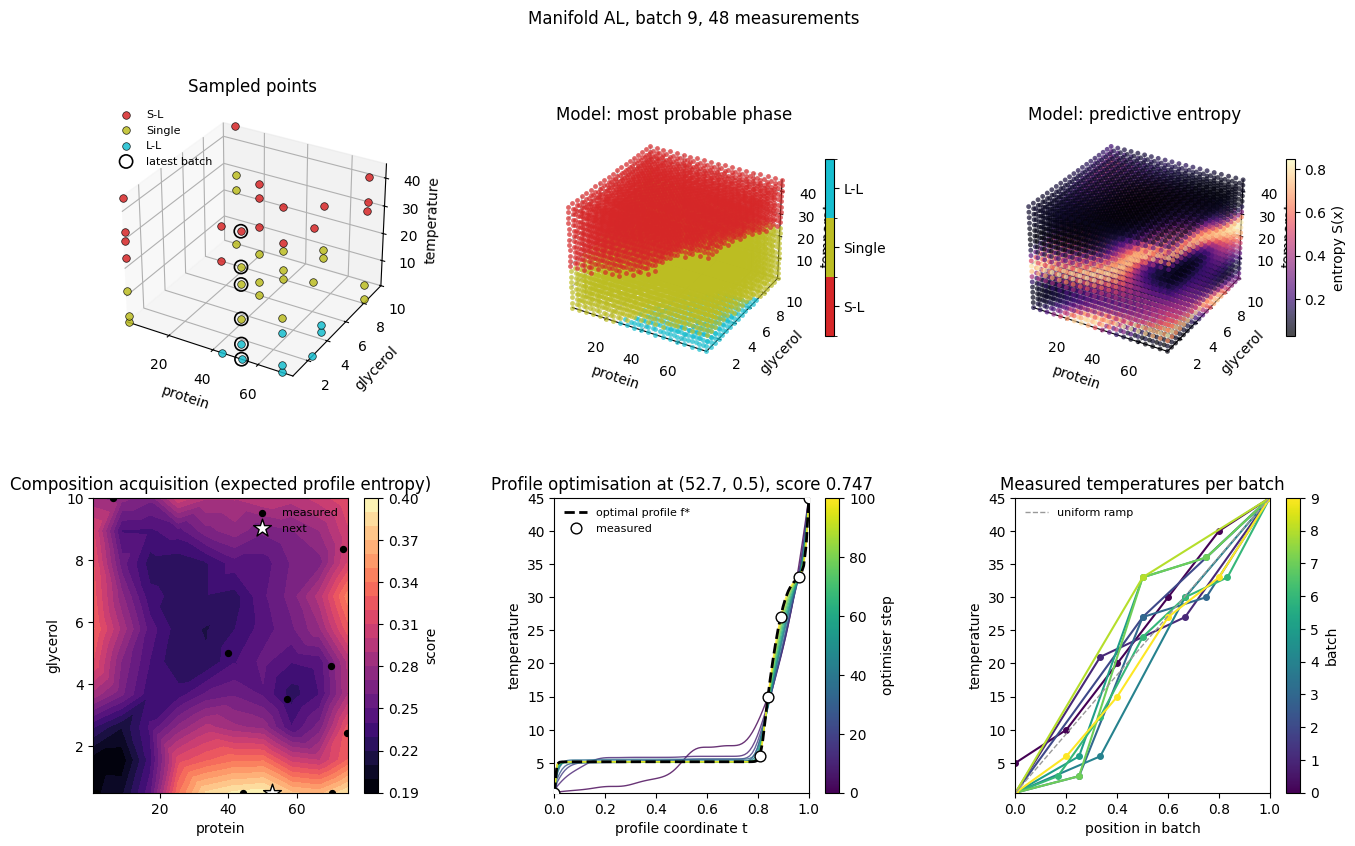

In [10]:
next_temperatures = get_temperature_profile(ds_result.profile_function.values, BOUNDS_T, **PROFILE)
plot_manifold_iteration(ds_result, ds_running, N_SAMPLES - 1, next_temperatures, temperature_history, LIMITS, COMPONENTS)
plt.show()

Compare the fitted phase map with the ground truth from section 2. Unlike the grid-based baseline, the temperature profiles are free to concentrate their points where the classifier is uncertain, so the number and spacing of the temperatures changes from batch to batch.